# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Sajal Porey <br>
**Roll Number:** AP24110011895 <br>
**Date:** 9/10/2026 <br>

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*
A 70/30 split has higher entropy.

Entropy measures uncertainty:
- In a 90/10 split, the label is easy to guess because guessing the majority class gives a 90% chance of being right (very low surprise/uncertainty).
- In a 70/30 split, classes are closer to an even 50/50 mix, meaning there is a 30% chance of being wrong. The label is much harder to guess, so the entropy is higher.


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [6]:
# Write your answer here
h_parent=entropy([8,6])
h_left=entropy([6,0])
h_right=entropy([2,6])
weighted_child_entropy=(6/14)*h_left+(8/14)*h_right
ig = h_parent-weighted_child_entropy

print(f"Parent Entropy:   {h_parent:.4f}")
print(f"Left Child H:     {h_left:.4f}")
print(f"Right Child H:    {h_right:.4f}")
print(f"Information Gain: {ig:.4f}")


Parent Entropy:   0.9852
Left Child H:     0.0000
Right Child H:    0.8113
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [7]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [8]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [9]:
for attr in ['Outlook', 'Temperature', 'Humidity']:
    print(f"Gain({attr}): {info_gain(tennis, attr):.4f}")

root_attr = max(['Outlook', 'Temperature', 'Humidity', 'Wind'], key=lambda a: info_gain(tennis, a))
print(f"Root picked: {root_attr}")

sunny_df = tennis[tennis['Outlook'] == 'Sunny']
print("Sunny branch gains:")
for attr in ['Temperature', 'Humidity', 'Wind']:
    print(f"  Gain({attr}): {info_gain(sunny_df, attr):.4f}")

rain_df = tennis[tennis['Outlook'] == 'Rain']
print("Rain branch gains:")
for attr in ['Temperature', 'Humidity', 'Wind']:
    print(f"  Gain({attr}): {info_gain(rain_df, attr):.4f}")

Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518
Root picked: Outlook
Sunny branch gains:
  Gain(Temperature): 0.5710
  Gain(Humidity): 0.9710
  Gain(Wind): 0.0200
Rain branch gains:
  Gain(Temperature): 0.0200
  Gain(Humidity): 0.0200
  Gain(Wind): 0.9710


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:* A pure branch contains samples that all belong to the exact same class (here, all 4 instances of Overcast have Play = Yes), which means its entropy is already 0.0.

Because there is zero uncertainty left, any further split would yield an Information Gain of 0 while adding unnecessary complexity. The decision is already deterministic, so the node can immediately become a leaf predicting that class.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


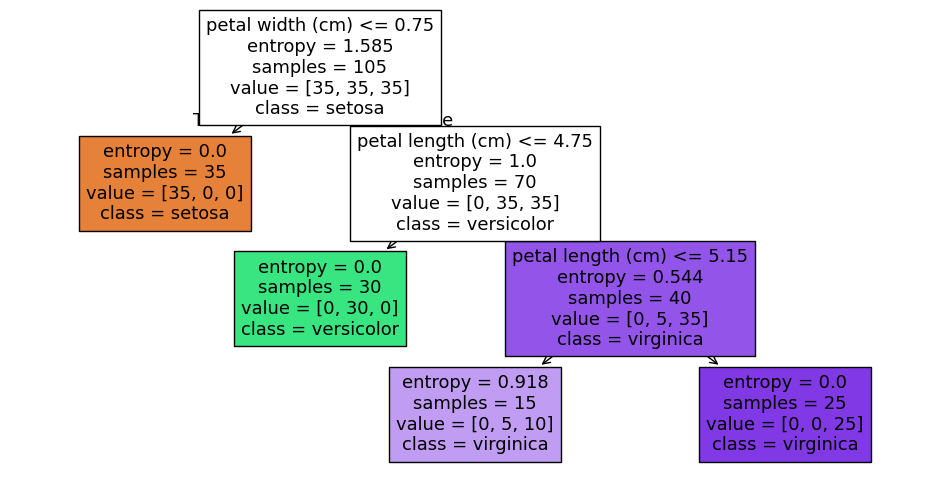

In [10]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


Best test accuracy: 0.9778 at max_depth = 5


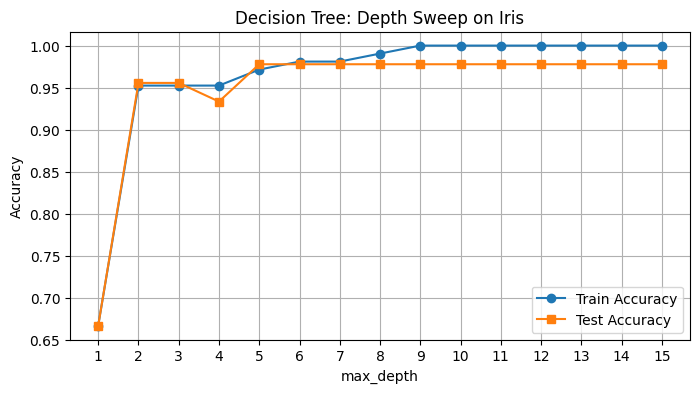

In [11]:
# Write your answer here
depths = range(1, 16)
train_acc = []
test_acc = []

for d in depths:
    clf = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=1)
    clf.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, clf.predict(X_train)))
    test_acc.append(accuracy_score(y_test, clf.predict(X_test)))

best_idx = np.argmax(test_acc)
best_depth = depths[best_idx]
print(f"Best test accuracy: {test_acc[best_idx]:.4f} at max_depth = {best_depth}")

plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc, marker='o', label='Train Accuracy')
plt.plot(depths, test_acc, marker='s', label='Test Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Depth Sweep on Iris')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:* Underfitting (Model too simple): Happens with very low max_depth (like 1), degree = 1, or very large K. The model is too rigid to learn patterns, so both training and testing accuracy stay low.

Overfitting (Model too complex): Happens with very high or unrestricted max_depth, high polynomial degree, or K = 1. The model memorizes training noise instead of learning general rules, giving high training accuracy but poor testing accuracy.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [13]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Unscaled Tree test accuracy (unrestricted depth): 0.8815
Test accuracy at max_depth =  3: 0.5296
Test accuracy at max_depth =  6: 0.8537
Test accuracy at max_depth = 10: 0.8796


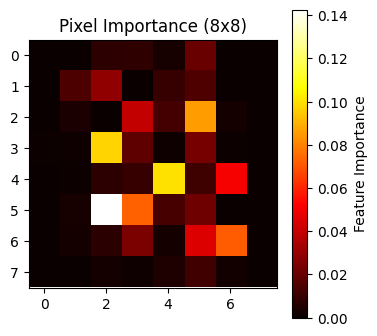

In [14]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)
acc = accuracy_score(yd_test, tree.predict(Xd_test))
print(f"Unscaled Tree test accuracy (unrestricted depth): {acc:.4f}")

for depth in [3, 6, 10]:
    t = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    t.fit(Xd_train, yd_train)
    t_acc = accuracy_score(yd_test, t.predict(Xd_test))
    print(f"Test accuracy at max_depth = {depth:2d}: {t_acc:.4f}")

importance_map = tree.feature_importances_.reshape(8, 8)
plt.figure(figsize=(4, 4))
plt.imshow(importance_map, cmap='hot', interpolation='nearest')
plt.colorbar(label='Feature Importance')
plt.title('Pixel Importance (8x8)')
plt.show()

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [15]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [17]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(X_text, labels)
tree_rules = export_text(tree, feature_names=vocab)
print("Tree Structure:")
print(tree_rules)

s1 = 'the striker scored a goal'
s2 = 'the apple was sweet and juicy'

v1 = to_vector(s1, vocab).reshape(1, -1)
v2 = to_vector(s2, vocab).reshape(1, -1)

pred1 = tree.predict(v1)[0]
pred2 = tree.predict(v2)[0]

print(f"'{s1}' -> {pred1}")
print(f"'{s2}' -> {pred2}")

Tree Structure:
|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

'the striker scored a goal' -> sports
'the apple was sweet and juicy' -> cooking


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* No, I would not expect the same split words.

Right now, the tree is splitting on accidental artifacts like "and", "has", and "laptop" simply because they happened to appear in the tiny training sample. Adding more sentences would introduce new vocabulary and distribute common words across multiple categories, changing the information gain calculations and altering the tree structure.

This shows that a decision tree trained on very little data has high variance and suffers from extreme overfitting. It memorizes coincidental patterns rather than true semantic meaning, making it brittle and unreliable for general text classification.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
